In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("credit_card_fraud_drift_2026.csv")

df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,TX4042000000000,CU00022008,CA000000001,ME000381,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,TX4042000000001,CU00000598,CA000000002,ME000764,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,TX4042000000002,CU00018179,CA000000003,ME001251,2026-01-01 00:03:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,TX4042000000003,CU00023636,CA000000004,ME002627,2026-01-01 00:04:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,TX4042000000004,CU00028521,CA000000005,ME004940,2026-01-01 00:05:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period


In [ ]:
df[['transaction_hour', 'transaction_day_of_week', 'is_weekend']].head()

,transaction_hour,transaction_day_of_week,is_weekend
0,0,Thursday,0
1,0,Thursday,0
2,0,Thursday,0
3,0,Thursday,0
4,0,Thursday,0


In [ ]:
df.isnull().sum()

,0
transaction_id,0
customer_id,0
card_id,0
merchant_id,0
transaction_datetime,0
...,...
dispute_adjudicated_friendly_fraud,0
dispute_delay_days,117307
dispute_event_datetime,117307
adjudication_datetime,117307


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
transaction_id,0.000000
customer_id,0.000000
card_id,0.000000
merchant_id,0.000000
transaction_datetime,0.000000
...,...
dispute_adjudicated_friendly_fraud,0.000000
dispute_delay_days,97.755833
dispute_event_datetime,97.755833
adjudication_datetime,97.755833


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
transaction_id,0.000000
customer_id,0.000000
card_id,0.000000
merchant_id,0.000000
transaction_datetime,0.000000
...,...
dispute_adjudicated_friendly_fraud,0.000000
dispute_delay_days,97.755833
dispute_event_datetime,97.755833
adjudication_datetime,97.755833


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['transaction_id'].duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
transaction_id,object
customer_id,object
card_id,object
merchant_id,object
transaction_datetime,object
...,...
dispute_adjudicated_friendly_fraud,int64
dispute_delay_days,float64
dispute_event_datetime,object
adjudication_datetime,object


In [ ]:
date_cols = [
    'transaction_datetime',
    'dispute_event_datetime',
    'adjudication_datetime'
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')


In [ ]:
df[date_cols].dtypes

,0
transaction_datetime,datetime64[ns]
dispute_event_datetime,datetime64[ns]
adjudication_datetime,datetime64[ns]


In [ ]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

df.dtypes

,0
transaction_id,object
customer_id,object
card_id,object
merchant_id,object
transaction_datetime,datetime64[ns]
month,int64
week_of_year,int64
drift_phase,int64
days_into_phase,int64
drift_magnitude,float64


In [ ]:
df.describe()

,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,failed_auth_attempts_24h,device_change_7d,billing_shipping_mismatch,account_profile_change_7d,merchant_velocity_24h,prior_dispute_ratio_90d,pos_entry_fallback,pin_retry_count_24h,concept_drift_score,population_shift_index,covariate_shift_flag,synthetic_id_camouflage_score,label_available,label_delay_days,pseudo_label,is_fraud,fraud_amount_lost,post_transaction_outcome,transaction_time_eligible,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime
count,120000,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,2693.000000,2693,2693
mean,2026-04-01 12:49:21.238000128,3.509708,13.86245,2.342708,24.584083,0.316672,46.327703,11.466783,0.488842,41.858283,846.398217,6723.963638,688.698575,2.816892,0.131967,0.422583,0.152442,10.733417,1.039151,42.568283,18.299366,16.712956,0.118175,0.065058,1.271503,0.37705,0.317058,0.285958,48.445102,13.415214,0.013892,0.072158,0.255383,0.113650,0.062967,0.046042,0.389792,0.019701,0.184308,0.148783,0.323744,0.308713,0.453533,0.002876,0.900583,11.804117,-0.891217,0.094892,4.295675,0.004392,0.984225,0.022442,0.008500,30.857779,2026-05-02 14:48:12.387671552,2026-05-18 00:41:12.632751872
min,2026-01-01 00:00:00,1.000000,1.00000,1.000000,0.000000,0.000000,1.500000,0.000000,0.000000,18.000000,15.000000,500.000000,300.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.110000,0.030000,0.000000,0.000000,0.020000,0.00000,0.000000,0.000000,1.580000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2026-01-05 02:15:00,2026-01-07 02:15:00
25%,2026-02-15 06:54:45,2.000000,7.00000,1.000000,11.000000,0.000000,22.720000,5.000000,0.000000,32.000000,311.000000,3202.400000,646.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,11.190000,5.280000,4.210000,0.000000,0.000000,0.475600,0.00000,0.000000,0.000000,41.430000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000400,0.080700,0.000000,0.000000,1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,16.000000,2026-03-18 04:12:00,2026-04-01 09:41:00
50%,2026-04-01 15:51:30,4.000000,14.00000,3.000000,22.000000,0.480000,36.290000,11.000000,0.000000,42.000000,537.000000,5200.110000,689.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,31.617000,10.650000,8.850000,0.000000,0.000000,0.815600,0.00000,0.000000,0.000000,50.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.408450,0.325250,0.000000,0.000000,1.000000,7.000000,-1.000000,0.000000,0.000000,0.

In [ ]:
num_cols = df.select_dtypes(include='number').columns

summary = df[num_cols].describe().T

summary[['min', 'max', 'mean', '50%']]

,min,max,mean,50%
month,1.00,6.0000,3.509708,4.00000
week_of_year,1.00,27.0000,13.862450,14.00000
drift_phase,1.00,4.0000,2.342708,3.00000
days_into_phase,0.00,60.0000,24.584083,22.00000
drift_magnitude,0.00,0.7800,0.316672,0.48000
transaction_amount,1.50,1030.5900,46.327703,36.29000
transaction_hour,0.00,23.0000,11.466783,11.00000
card_present,0.00,1.0000,0.488842,0.00000
customer_age,18.00,90.0000,41.858283,42.00000
account_age_days,15.00,24603.0000,846.398217,537.00000


In [ ]:
(df[num_cols] < 0).sum()

,0
month,0
week_of_year,0
drift_phase,0
days_into_phase,0
drift_magnitude,0
transaction_amount,0
transaction_hour,0
card_present,0
customer_age,0
account_age_days,0


In [ ]:
(df[num_cols] < 0).sum().sort_values(ascending=False).head(10)

,0
pseudo_label,108070
week_of_year,0
drift_phase,0
days_into_phase,0
month,0
transaction_amount,0
transaction_hour,0
card_present,0
customer_age,0
account_age_days,0


In [ ]:
print(df.shape)
print(df['pseudo_label'].dtype)
print(df['pseudo_label'].value_counts(dropna=False))

(120000, 73)
int64
pseudo_label
-1    108070
 0     10806
 1      1124
Name: count, dtype: int64


In [ ]:
df['is_fraud'].value_counts()

,count
is_fraud,
0,108613
1,11387


In [ ]:
df['is_fraud'].value_counts(normalize=True) * 100

,proportion
is_fraud,
0,90.510833
1,9.489167


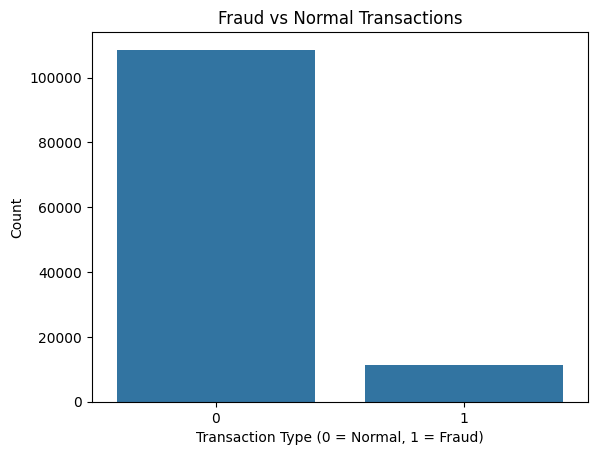

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=df, x='is_fraud')
plt.title('Fraud vs Normal Transactions')
plt.xlabel('Transaction Type (0 = Normal, 1 = Fraud)')
plt.ylabel('Count')
plt.show()

In [ ]:
df.groupby('is_fraud')['transaction_amount'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
is_fraud,,,,,
0,108613,43.887321,34.87,1.50,853.06
1,11387,69.604877,54.84,4.05,1030.59


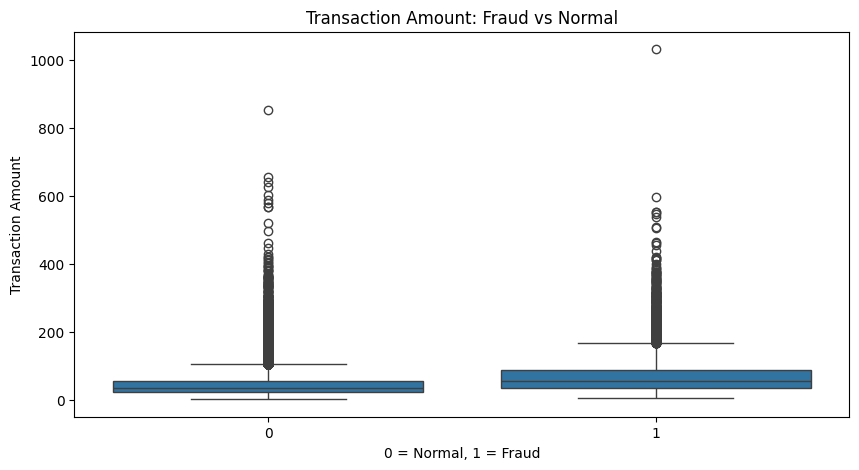

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='is_fraud', y='transaction_amount')

plt.title('Transaction Amount: Fraud vs Normal')
plt.xlabel('0 = Normal, 1 = Fraud')
plt.ylabel('Transaction Amount')

plt.show()

In [ ]:
fraud_by_category = df[df['is_fraud'] == 1]['merchant_category'].value_counts()
fraud_by_category

,count
merchant_category,
retail,2027
grocery,1790
restaurant,1496
fuel,1221
digital_goods,963
electronics,959
subscription,917
health,830
travel,707


In [ ]:
fraud_rate = df.groupby('merchant_category')['is_fraud'].mean() * 100
fraud_rate.sort_values(ascending=False)

,is_fraud
merchant_category,
subscription,10.108025
health,9.815516
cash_withdrawal,9.800699
digital_goods,9.789570
fuel,9.530872
retail,9.505721
electronics,9.378973
travel,9.292850
grocery,9.242049


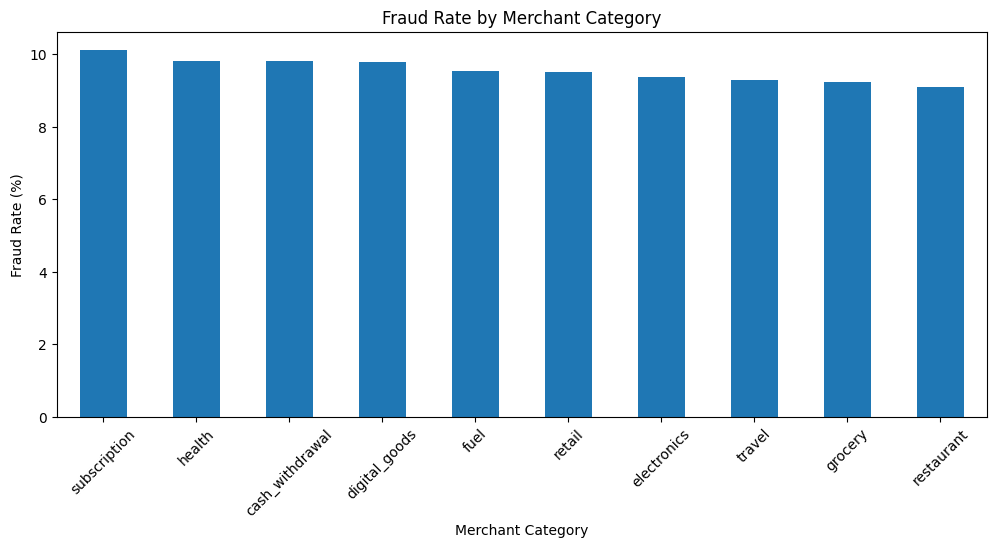

In [ ]:
plt.figure(figsize=(12, 5))

fraud_rate.sort_values(ascending=False).plot(kind='bar')

plt.title('Fraud Rate by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
fraud_by_hour = df.groupby('transaction_hour')['is_fraud'].mean() * 100
fraud_by_hour

,is_fraud
transaction_hour,
0,9.472233
1,10.695617
2,9.966317
3,9.623601
4,9.115914
5,9.515152
6,9.054647
7,9.241848
8,9.566075


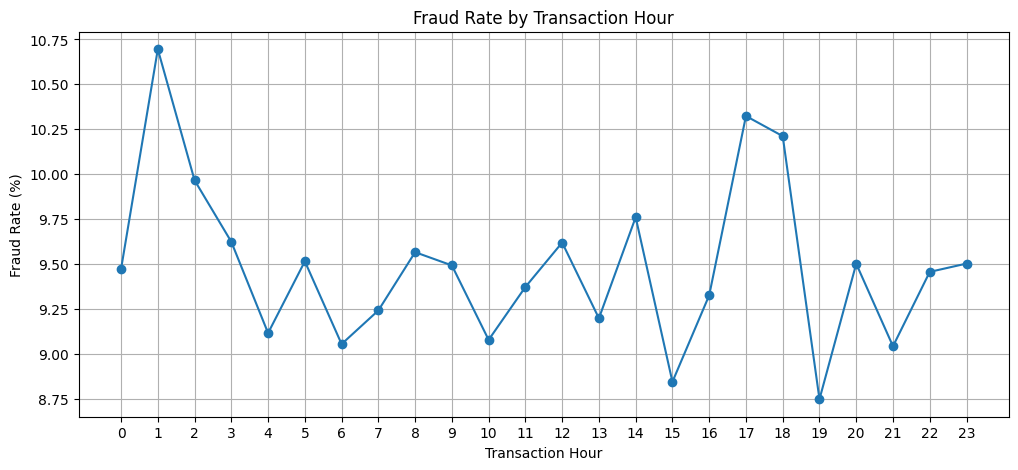

In [ ]:
plt.figure(figsize=(12, 5))

fraud_by_hour.plot(kind='line', marker='o')

plt.title('Fraud Rate by Transaction Hour')
plt.xlabel('Transaction Hour')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(24))
plt.grid()
plt.show()

In [ ]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']

fraud_by_day = (
    df.groupby('transaction_day_of_week')['is_fraud'].mean() * 100
).reindex(day_order)

fraud_by_day

,is_fraud
transaction_day_of_week,
Monday,9.447353
Tuesday,9.687947
Wednesday,9.533566
Thursday,9.292545
Friday,9.310224
Saturday,9.703504
Sunday,9.449823


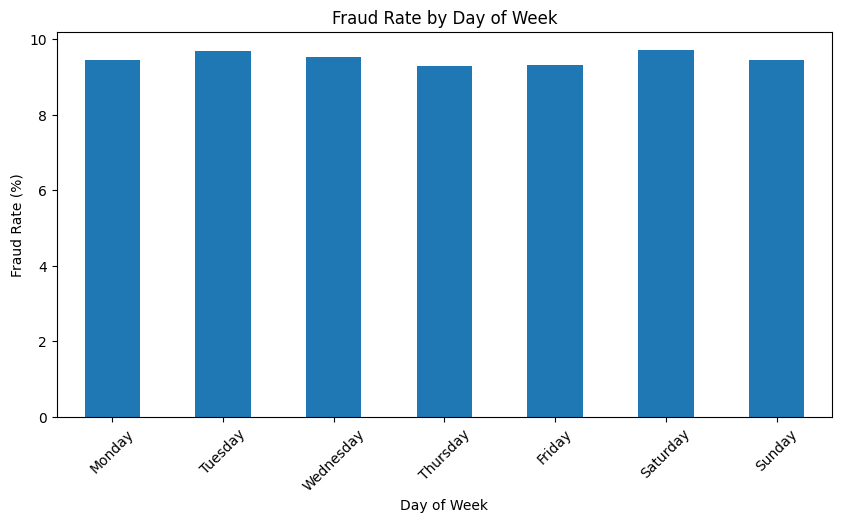

In [ ]:
plt.figure(figsize=(10, 5))
fraud_by_day.plot(kind='bar')
plt.title('Fraud Rate by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
df.groupby('is_weekend')['is_fraud'].mean() * 100

,is_fraud
is_weekend,
0,9.454397
1,9.575987


In [ ]:
fraud_by_channel = df.groupby('transaction_channel')['is_fraud'].mean() * 100

fraud_by_channel.sort_values(ascending=False)

,is_fraud
transaction_channel,
mobile_app,13.479089
recurring,12.317328
ecommerce,11.426148
ATM,7.241798
POS,6.558356


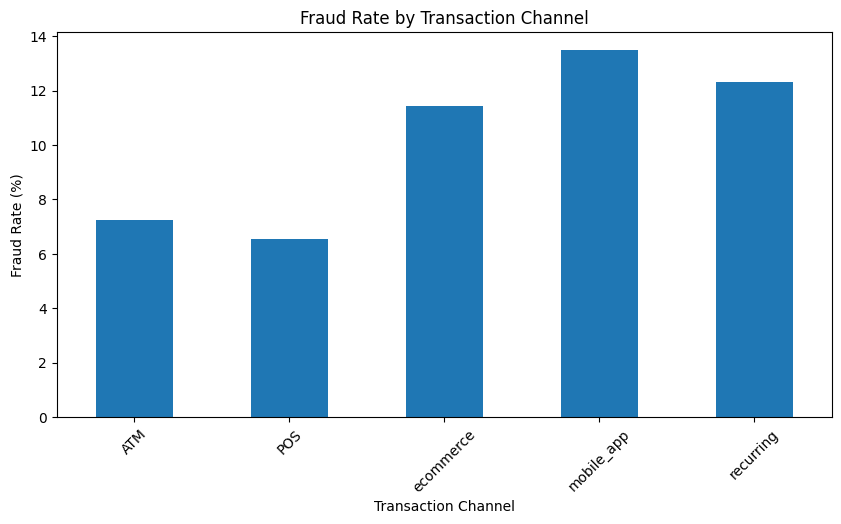

In [ ]:
plt.figure(figsize=(10, 5))
fraud_by_channel.plot(kind='bar')
plt.title('Fraud Rate by Transaction Channel')
plt.xlabel('Transaction Channel')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
fraud_by_card = df.groupby('card_present')['is_fraud'].mean() * 100
fraud_by_card

,is_fraud
card_present,
0,11.888032
1,6.980788


In [ ]:
df['is_fraud'].isnull().sum()

np.int64(0)

In [ ]:
df_ml = df.dropna(subset=['is_fraud']).copy()
df_ml.shape

(120000, 73)

In [ ]:
leakage_cols = [
    'fraud_type',
    'fraud_amount_lost',
    'post_transaction_outcome',
    'dispute_filed',
    'dispute_adjudicated_friendly_fraud',
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime'
]

In [ ]:
df_ml[leakage_cols].head()

,fraud_type,fraud_amount_lost,post_transaction_outcome,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime
0,Legitimate,0.0,0,0,0,NaN,NaT,NaT
1,Legitimate,0.0,0,0,0,NaN,NaT,NaT
2,Legitimate,0.0,0,0,0,NaN,NaT,NaT
3,Legitimate,0.0,0,0,0,NaN,NaT,NaT
4,Legitimate,0.0,0,0,0,NaN,NaT,NaT


In [ ]:
remaining_cols = [
    col for col in df_ml.columns
    if col not in leakage_cols + ['is_fraud']
]

print(remaining_cols)

['transaction_id', 'customer_id', 'card_id', 'merchant_id', 'transaction_datetime', 'month', 'week_of_year', 'drift_phase', 'days_into_phase', 'drift_magnitude', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'email_domain', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', '

In [ ]:
id_cols = [
    'transaction_id',
    'customer_id',
    'card_id',
    'merchant_id'
]
candidate_features = [
    col for col in remaining_cols
    if col not in id_cols
]

In [ ]:
print(candidate_features)

['transaction_datetime', 'month', 'week_of_year', 'drift_phase', 'days_into_phase', 'drift_magnitude', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'email_domain', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pos_ent

In [ ]:
len(candidate_features)

60

In [ ]:
review_cols = [
    'label_available',
    'label_delay_days',
    'pseudo_label',
    'transaction_time_eligible',
    'transaction_time_target',
    'drift_phase',
    'drift_magnitude',
    'concept_drift_score',
    'population_shift_index',
    'covariate_shift_flag',
    'synthetic_id_camouflage_score',
    'drift_phase_name',
    'dispute_regime'
]
provisional_features = [
    col for col in candidate_features
    if col not in review_cols
]
len(provisional_features)

47

In [ ]:
df_ml[provisional_features].dtypes

,0
transaction_datetime,datetime64[ns]
month,int64
week_of_year,int64
days_into_phase,int64
transaction_amount,float64
merchant_category,object
merchant_country,object
transaction_hour,int64
transaction_day_of_week,object
card_present,int64


In [ ]:
df_ml[provisional_features].select_dtypes(include='object').columns.tolist()

['merchant_category',
 'merchant_country',
 'transaction_day_of_week',
 'customer_gender',
 'customer_country',
 'transaction_channel',
 'device_type',
 'browser',
 'email_domain']

In [ ]:
df_ml[provisional_features].select_dtypes(include='datetime').columns.tolist()

['transaction_datetime']

In [ ]:
df_ml[provisional_features].select_dtypes(include=['int64', 'float64']).columns.tolist()

['month',
 'week_of_year',
 'days_into_phase',
 'transaction_amount',
 'transaction_hour',
 'card_present',
 'customer_age',
 'account_age_days',
 'credit_limit',
 'credit_score',
 'num_cards_held',
 'transactions_last_1h',
 'transactions_last_24h',
 'transactions_last_7d',
 'amount_last_1h',
 'amount_last_24h',
 'days_since_last_transaction',
 'distance_from_home_km',
 'distance_from_last_tx_km',
 'international_transaction',
 'high_risk_country',
 'amount_vs_avg_ratio',
 'used_chip',
 'used_pin',
 'is_weekend',
 'avg_transaction_amount_30d',
 'std_transaction_amount_30d',
 'num_declined_last_30d',
 'num_chargebacks_ever',
 'failed_auth_attempts_24h',
 'device_change_7d',
 'billing_shipping_mismatch',
 'account_profile_change_7d',
 'merchant_velocity_24h',
 'prior_dispute_ratio_90d',
 'pos_entry_fallback',
 'pin_retry_count_24h']

In [ ]:
time_cols = [
    'transaction_hour',
    'transaction_day_of_week',
    'month',
    'is_weekend'
]

[col for col in time_cols if col in df_ml.columns]

['transaction_hour', 'transaction_day_of_week', 'month', 'is_weekend']

In [ ]:
review_cols.append('transaction_datetime')

In [ ]:
provisional_features = [
    col for col in candidate_features
    if col not in review_cols
]

In [ ]:
len(provisional_features)

46

In [ ]:
review_cols

['label_available',
 'label_delay_days',
 'pseudo_label',
 'transaction_time_eligible',
 'transaction_time_target',
 'drift_phase',
 'drift_magnitude',
 'concept_drift_score',
 'population_shift_index',
 'covariate_shift_flag',
 'synthetic_id_camouflage_score',
 'drift_phase_name',
 'dispute_regime',
 'transaction_datetime']

In [ ]:
X = df_ml[provisional_features].copy()
y = df_ml['is_fraud'].copy()

In [ ]:
X.select_dtypes(include='object').columns.tolist()

['merchant_category',
 'merchant_country',
 'transaction_day_of_week',
 'customer_gender',
 'customer_country',
 'transaction_channel',
 'device_type',
 'browser',
 'email_domain']

In [ ]:
X.isnull().sum().sum()

np.int64(0)

In [ ]:
y.value_counts()

,count
is_fraud,
0,108613
1,11387


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(96000, 46)
(24000, 46)
(96000,)
(24000,)


In [ ]:
categorical_cols = X.select_dtypes(include='object').columns.tolist()
numerical_cols = X.select_dtypes(exclude='object').columns.tolist()

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Training:", X_train_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (96000, 105)
Testing: (24000, 105)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train_processed, y_train)
y_pred_lr = lr_model.predict(X_test_processed)
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     21723
           1       0.92      0.98      0.95      2277

    accuracy                           0.99     24000
   macro avg       0.96      0.99      0.97     24000
weighted avg       0.99      0.99      0.99     24000



In [ ]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)
print(cm_lr)

[[21530   193]
 [   47  2230]]


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)
dt_model.fit(X_train_processed, y_train)
y_pred_dt = dt_model.predict(X_test_processed)
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     21723
           1       1.00      0.99      0.99      2277

    accuracy                           1.00     24000
   macro avg       1.00      1.00      1.00     24000
weighted avg       1.00      1.00      1.00     24000



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_processed, y_train)
y_pred_rf = rf_model.predict(X_test_processed)
print(classification_report(y_test, y_pred_rf))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     21723
           1       1.00      0.98      0.99      2277

    accuracy                           1.00     24000
   macro avg       1.00      0.99      1.00     24000
weighted avg       1.00      1.00      1.00     24000



In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Fraud Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    'Fraud Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    'Fraud F1-score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

results.round(4)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1-score
0,Logistic Regression,0.9900,0.9203,0.9794,0.9489
1,Decision Tree,0.9988,0.9952,0.9917,0.9934
2,Random Forest,0.9983,1.0000,0.9824,0.9911


In [ ]:
#model 2 multi-classification

In [ ]:
df_ml.loc[df_ml['is_fraud'] == 1, 'fraud_type'].value_counts()

,count
fraud_type,
Card-Not-Present,2879
Account-Takeover,2571
Synthetic-Identity,2146
Card-Present,1898
Friendly-Fraud,1893


In [ ]:
df_fraud = df_ml[df_ml['is_fraud'] == 1].copy()

X2 = df_fraud[provisional_features].copy()
y2 = df_fraud['fraud_type'].copy()
from sklearn.model_selection import train_test_split

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.2,
    random_state=42,
    stratify=y2
)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols2 = X2.select_dtypes(include='object').columns.tolist()
numerical_cols2 = X2.select_dtypes(exclude='object').columns.tolist()

preprocessor2 = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols2),
        ('num', StandardScaler(), numerical_cols2)
    ]
)

X2_train_processed = preprocessor2.fit_transform(X2_train)
X2_test_processed = preprocessor2.transform(X2_test)

In [ ]:
print("Training shape:", X2_train_processed.shape)
print("Testing shape:", X2_test_processed.shape)

Training shape: (9109, 105)
Testing shape: (2278, 105)


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model2 = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
lr_model2.fit(X2_train_processed, y2_train)
y2_pred_lr = lr_model2.predict(X2_test_processed)
from sklearn.metrics import classification_report
print(classification_report(y2_test, y2_pred_lr))

                    precision    recall  f1-score   support

  Account-Takeover       0.99      0.98      0.99       514
  Card-Not-Present       0.93      0.88      0.90       576
      Card-Present       1.00      0.99      1.00       380
    Friendly-Fraud       0.99      0.99      0.99       379
Synthetic-Identity       0.85      0.92      0.89       429

          accuracy                           0.95      2278
         macro avg       0.95      0.95      0.95      2278
      weighted avg       0.95      0.95      0.95      2278



In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model2 = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)
dt_model2.fit(X2_train_processed, y2_train)
y2_pred_dt = dt_model2.predict(X2_test_processed)
print(classification_report(y2_test, y2_pred_dt))


                    precision    recall  f1-score   support

  Account-Takeover       0.96      0.91      0.94       514
  Card-Not-Present       0.84      0.86      0.85       576
      Card-Present       0.98      0.98      0.98       380
    Friendly-Fraud       0.97      0.96      0.97       379
Synthetic-Identity       0.85      0.87      0.86       429

          accuracy                           0.91      2278
         macro avg       0.92      0.92      0.92      2278
      weighted avg       0.91      0.91      0.91      2278



In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model2 = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model2.fit(X2_train_processed, y2_train)
y2_pred_rf = rf_model2.predict(X2_test_processed)
print(classification_report(y2_test, y2_pred_rf))
#

                    precision    recall  f1-score   support

  Account-Takeover       0.99      0.99      0.99       514
  Card-Not-Present       0.93      0.93      0.93       576
      Card-Present       0.99      1.00      1.00       380
    Friendly-Fraud       0.99      0.99      0.99       379
Synthetic-Identity       0.91      0.91      0.91       429

          accuracy                           0.96      2278
         macro avg       0.96      0.96      0.96      2278
      weighted avg       0.96      0.96      0.96      2278



In [ ]:
results2 = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y2_test, y2_pred_lr),
        accuracy_score(y2_test, y2_pred_dt),
        accuracy_score(y2_test, y2_pred_rf)
    ],
    'Macro F1-score': [
        f1_score(y2_test, y2_pred_lr, average='macro'),
        f1_score(y2_test, y2_pred_dt, average='macro'),
        f1_score(y2_test, y2_pred_rf, average='macro')
    ]
})

results2.round(4)

,Model,Accuracy,Macro F1-score
0,Logistic Regression,0.9486,0.9524
1,Decision Tree,0.9109,0.9176
2,Random Forest,0.9614,0.9640


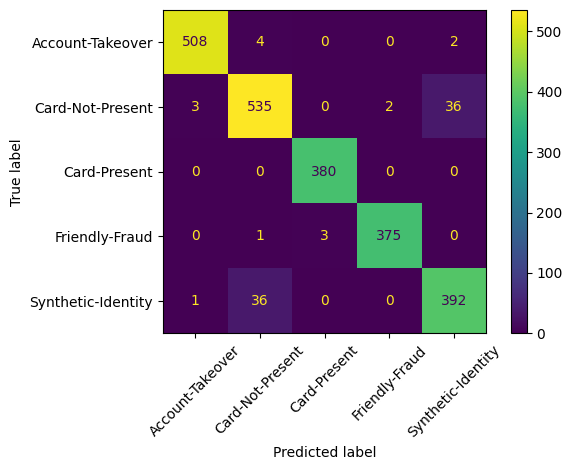

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm2 = confusion_matrix(y2_test, y2_pred_rf, labels=rf_model2.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm2,
    display_labels=rf_model2.classes_
)

disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# model 3 Transaction Pattern and Drift Analysis

In [ ]:
monthly_analysis = df_ml.groupby(
    df_ml['transaction_datetime'].dt.to_period('M')
).agg(
    Total_Transactions=('is_fraud', 'count'),
    Fraud_Transactions=('is_fraud', 'sum')
)

monthly_analysis['Fraud_Rate'] = (
    monthly_analysis['Fraud_Transactions'] /
    monthly_analysis['Total_Transactions'] * 100
)

monthly_analysis

,Total_Transactions,Fraud_Transactions,Fraud_Rate
transaction_datetime,,,
2026-01,20521,1909,9.302666
2026-02,18612,1808,9.714163
2026-03,20445,1905,9.317682
2026-04,19861,1870,9.415437
2026-05,20725,1979,9.548854
2026-06,19836,1916,9.659205


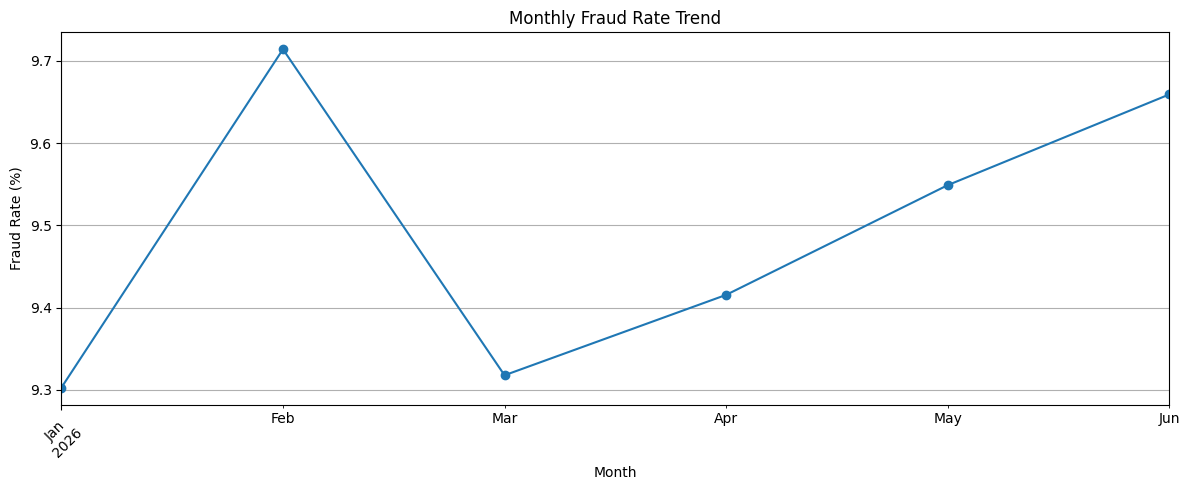

In [ ]:
import matplotlib.pyplot as plt

monthly_analysis['Fraud_Rate'].plot(
    figsize=(12, 5),
    marker='o'
)

plt.title('Monthly Fraud Rate Trend')
plt.xlabel('Month')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print(df_ml['transaction_datetime'].min())
print(df_ml['transaction_datetime'].max())
print(df_ml['transaction_datetime'].dt.to_period('M').nunique())

2026-01-01 00:00:00
2026-06-30 23:58:00
6


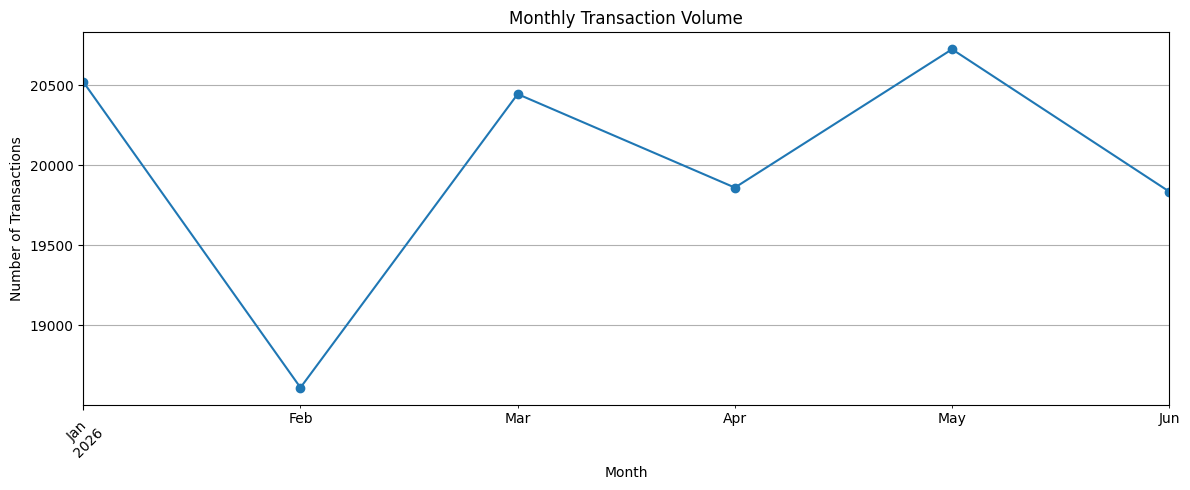

In [ ]:
monthly_analysis['Total_Transactions'].plot(
    figsize=(12, 5),
    marker='o'
)

plt.title('Monthly Transaction Volume')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
fraud_type_monthly = df_ml[df_ml['is_fraud'] == 1].pivot_table(
    index=df_ml[df_ml['is_fraud'] == 1]['transaction_datetime'].dt.to_period('M'),
    columns='fraud_type',
    values='is_fraud',
    aggfunc='count',
    fill_value=0
)

fraud_type_monthly

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Friendly-Fraud,Synthetic-Identity
transaction_datetime,,,,,
2026-01,434,491,287,351,346
2026-02,379,472,323,306,328
2026-03,429,501,355,304,316
2026-04,403,464,297,319,387
2026-05,459,474,326,322,398
2026-06,467,477,310,291,371


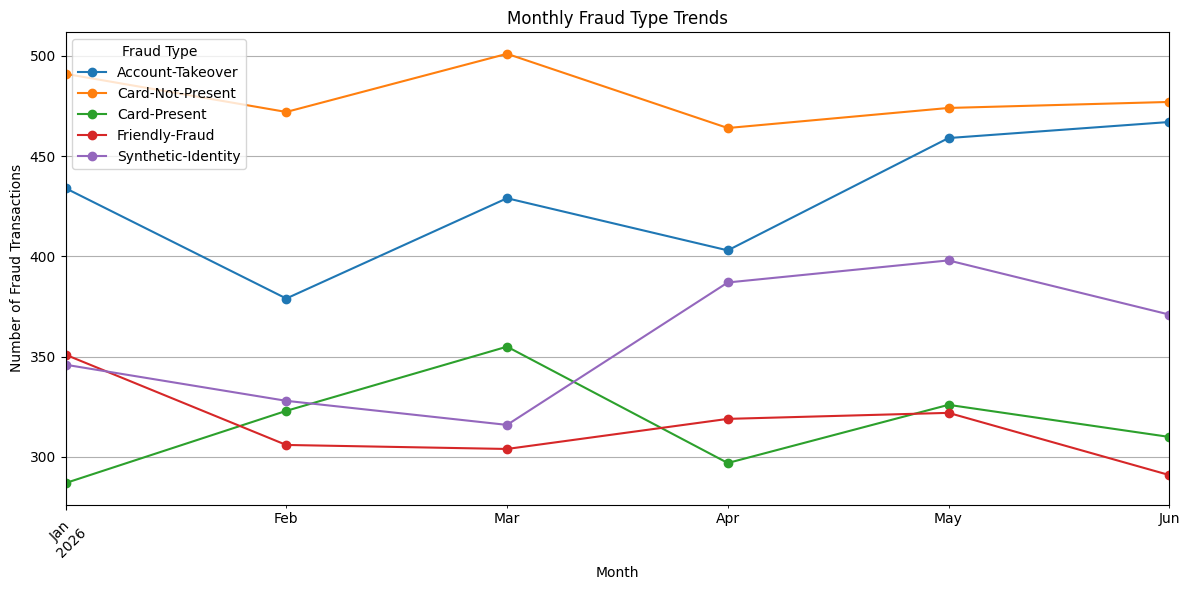

In [ ]:
fraud_type_monthly.plot(
    figsize=(12, 6),
    marker='o'
)

plt.title('Monthly Fraud Type Trends')
plt.xlabel('Month')
plt.ylabel('Number of Fraud Transactions')
plt.xticks(rotation=45)
plt.legend(title='Fraud Type')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
df_ml['drift_phase_name'].value_counts()

,count
drift_phase_name,
peak_drift,40586
stable_training,39133
pre_drift_validation,20445
partial_stabilization,19836


In [ ]:
drift_analysis = df_ml.groupby('drift_phase_name').agg(
    Total_Transactions=('is_fraud', 'count'),
    Fraud_Transactions=('is_fraud', 'sum')
)

drift_analysis['Fraud_Rate'] = (
    drift_analysis['Fraud_Transactions'] /
    drift_analysis['Total_Transactions'] * 100
)

drift_analysis

,Total_Transactions,Fraud_Transactions,Fraud_Rate
drift_phase_name,,,
partial_stabilization,19836,1916,9.659205
peak_drift,40586,3849,9.483566
pre_drift_validation,20445,1905,9.317682
stable_training,39133,3717,9.498377


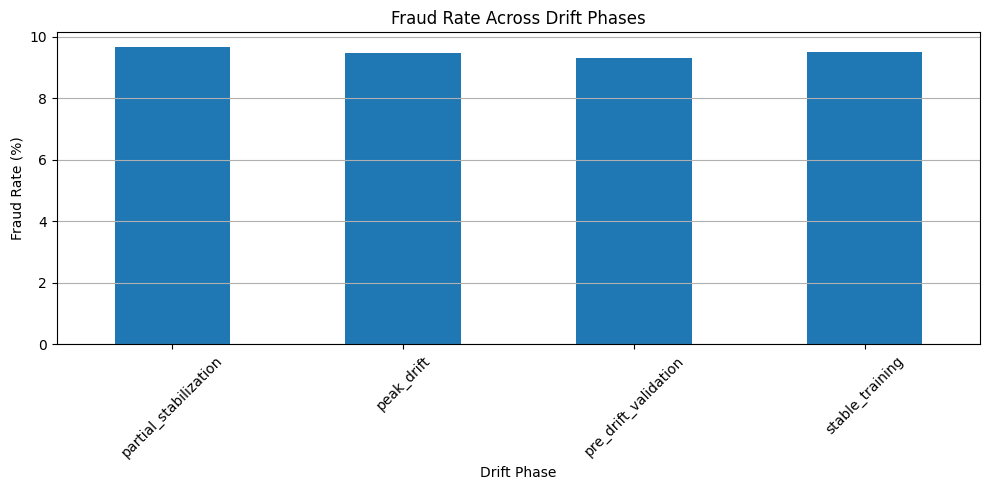

In [ ]:
drift_analysis['Fraud_Rate'].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Fraud Rate Across Drift Phases')
plt.xlabel('Drift Phase')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

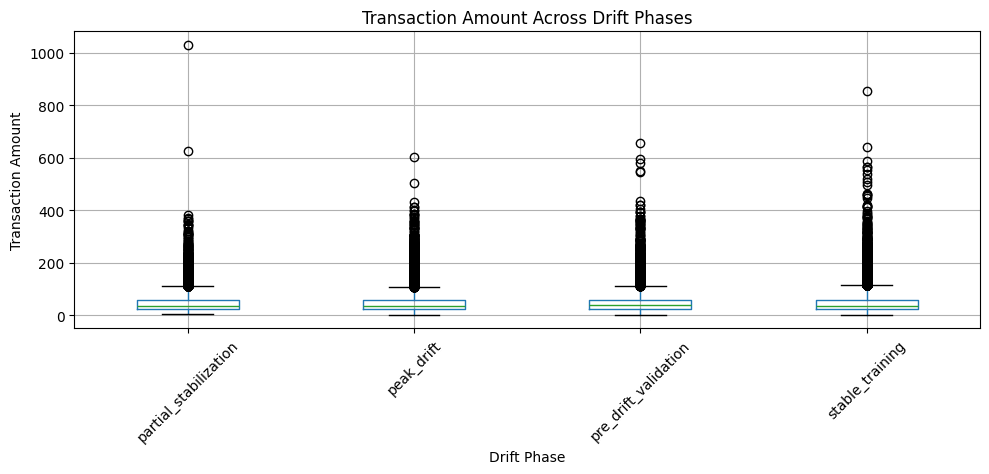

In [ ]:
df_ml.boxplot(
    column='transaction_amount',
    by='drift_phase_name',
    figsize=(10, 5)
)

plt.title('Transaction Amount Across Drift Phases')
plt.suptitle('')
plt.xlabel('Drift Phase')
plt.ylabel('Transaction Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
drift_indicators = df_ml.groupby(
    df_ml['transaction_datetime'].dt.to_period('M')
)[['concept_drift_score', 'population_shift_index']].mean()

drift_indicators

,concept_drift_score,population_shift_index
transaction_datetime,,
2026-01,0.014065,0.081700
2026-02,0.014037,0.081060
2026-03,0.013953,0.080920
2026-04,0.620165,0.526069
2026-05,0.780496,0.641646
2026-06,0.480001,0.426473


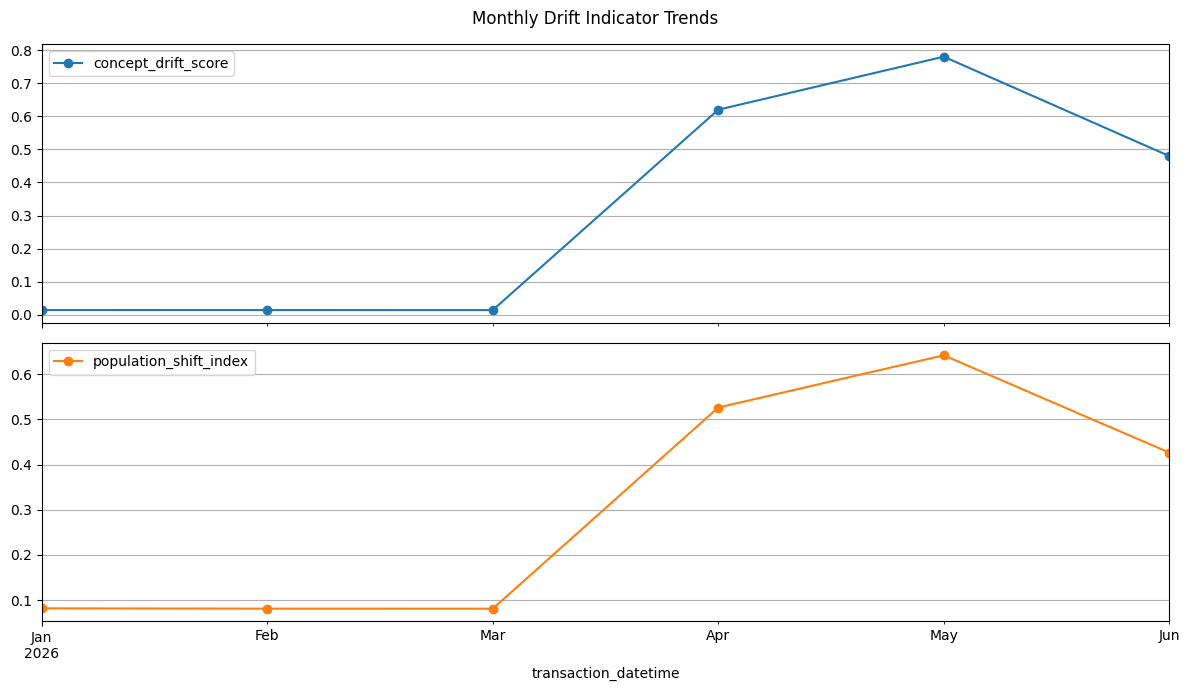

In [ ]:
drift_indicators.plot(
    subplots=True,
    figsize=(12, 7),
    marker='o',
    grid=True
)

plt.suptitle('Monthly Drift Indicator Trends')
plt.tight_layout()
plt.show()

In [ ]:
monthly_shift = df_ml.groupby(
    df_ml['transaction_datetime'].dt.to_period('M')
)['covariate_shift_flag'].value_counts().unstack(fill_value=0)

monthly_shift

covariate_shift_flag,0,1
transaction_datetime,,
2026-01,20521,0
2026-02,18612,0
2026-03,20445,0
2026-04,130,19731
2026-05,0,20725
2026-06,5868,13968
